In [1]:
%load_ext autoreload
%autoreload 2
# %matplotlib widget
%matplotlib inline

import os
import math
import sys
import torch
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

if not '../src' in sys.path:
    sys.path.append('../src')

from dataset import MuonDataset
from mappers import CustomMapper
from propagation import HighlandPropagator
from constants import *
from tools import *
from callbacks import ObservablesPlotCallback

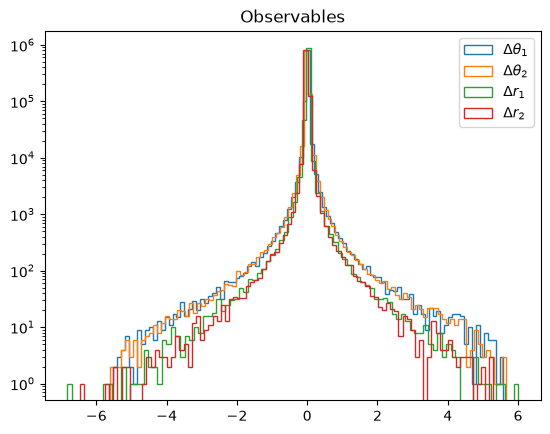

In [2]:
def selection(ri,rf,di,df):
    distance_mask =  (ri-rf).norm(dim=-1) > 0.05
    angle = torch.rad2deg(
        torch.acos(
            (di*df).sum(dim=-1)
        )
    )
    angle_mask = torch.logical_and(
        ~torch.isnan(angle),
        angle < 80.,
    )
    mask = torch.logical_and(distance_mask,angle_mask)
    return mask
    
dataset = MuonDataset.from_data_file(
    data_file = '/cephfs/dice/users/lw23382/MuonTransmissionData/data_uniform.npy',
    momentum_file = '/cephfs/dice/users/lw23382/MuonTransmissionData/momenta_uniform.npy',
    selection = selection,
)

fig = dataset.plot_observables(log=True)
plt.show()

In [3]:
def make_mapper(X0):
    lambda_min = min(1/X0s['Air'], 1/X0s['Fe'])
    lambda_max = max(1/X0s['Air'], 1/X0s['Fe'])
    
    air_lam_log = math.log10(1/X0s['Air'])
    core_lam_log = math.log10(1/X0s['Fe'])
    
    radius =  0.6
    center = torch.tensor([0., 0., 0.])
    transition_width = 0.1  # Make it a clean, visible boundary
    
    def func(x):
        lam_log = torch.ones((x.shape[0],1),device=x.device) * math.log10(1. / X0)
        lam_normalized = 2 * (lam_log - air_lam_log) / (core_lam_log - air_lam_log) - 1
        return lam_normalized
    
    mapper = CustomMapper(
        xlow = [0.,0.,0.],  # Adjust to your volume coordinate bounds
        xhigh = [1, 1, 1],
        ylow = 1/X0s['Air'],   # Pass actual positive lower physical bound
        yhigh = 1/X0s['Fe'],   # Pass actual positive upper physical bound
        func = func,
    )
    return mapper

In [4]:
n_samples = 10
N = 10000
X0_true = X0s['Ca']
lam_true = 1/X0_true

propagator = HighlandPropagator(
    step_size = 0.01,
)
propagator.low = torch.tensor([0.,0.,0.])
propagator.high = torch.tensor([1.,1.,1.])


ri = dataset.ri[dataset.mask][:N]
di = dataset.di[dataset.mask][:N]
pi = dataset.pi[dataset.mask][:N]
true_obs = dataset._observables[dataset.mask][:N].unsqueeze(1)

ri = ri.unsqueeze(1).expand(-1, n_samples, -1).reshape(N*n_samples,-1)
di = di.unsqueeze(1).expand(-1, n_samples, -1).reshape(N*n_samples,-1)
pi = pi.unsqueeze(1).expand(-1, n_samples, -1).reshape(N*n_samples,-1)

lams = np.logspace(math.log10(1/X0s['U']),math.log10(1/X0s['Air']),20)
dists = []

for lam in lams:
    X0 = 1/lam
    print ('X0',X0,X0_true)
    print ('lam',lam,lam_true)
    mapper = make_mapper(X0)
    # fig = mapper.plot_slice(
    #     direction = 'y',
    #     value = 0.5,
    #     low = [0,0],
    #     high = [1,1],
    #     batch_size = 5000,
    #     points = 20,
    #     show_materials = False,
    # )
    plt.show()

    with torch.no_grad():
        rf, df, pf = propagator.propagate(
            mapper = mapper,
            ri = ri,
            di = di,
            pi = pi,
        )
    a1, a2, s1, s2 = positions_to_observables(
        ri = ri,
        di = di,
        rf = rf,
        df = df,
        lo = dataset.low,
        hi = dataset.high,
    )
    samp_obs = torch.stack([a1, a2, s1, s2]).reshape(N,n_samples,-1)
    
    mask = selection(ri,rf,di,df).reshape(N,n_samples)
    mask = mask.all(dim=-1)
    samp_obs_mask = samp_obs[mask]
    true_obs_mask = true_obs[mask]

    # callback = ObservablesPlotCallback(frequency=10)
    # fig = callback.on_observables_end(None,samp_obs[:,0],true_obs[:,0],dataset.observable_names)
    # plt.show()

    att,rep = energy_distance_loss(true_obs_mask,samp_obs_mask,gamma=0)
    loss = att+rep
    print (loss)
    dists.append(loss) 
    print ('-'*60)
    

X0 0.003166000000000001 0.1042
lam 315.8559696778268 9.596928982725528
Propagation : [====================================================================================================] 100%
Propagation done in 1535 steps, max distance 1.558
tensor(0.1555)
------------------------------------------------------------
X0 0.005790725850958959 0.1042
lam 172.68992277270345 9.596928982725528
Propagation : [====================================================================================================] 100%
Propagation done in 981 steps, max distance 1.578
tensor(0.1230)
------------------------------------------------------------
X0 0.010591442160759426 0.1042
lam 94.4158486466491 9.596928982725528
Propagation : [====================================================================================================] 100%
Propagation done in 1590 steps, max distance 1.551
tensor(0.1024)
------------------------------------------------------------
X0 0.019372121894897714 0.1042
lam 51.620

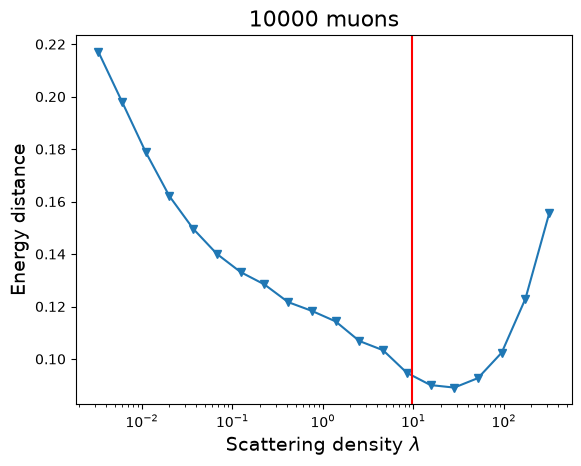

In [5]:
plt.plot(
    lams,
    dists,
    marker = 'v',
)
plt.xscale('log')
plt.axvline(lam_true,color='r')
plt.xlabel(r'Scattering density $\lambda$',fontsize=14)
plt.ylabel(r'Energy distance',fontsize=14)
plt.title(f'{N} muons',fontsize=16)
plt.show()